<a href="https://colab.research.google.com/github/gyeongee/TIL/blob/main/%EB%8B%A4%EC%A4%91%EB%B6%84%EB%A5%98_%EC%8B%AC%EC%B8%B5%EC%8B%A0%EA%B2%BD%EB%A7%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

각 클래스별 확률 값이 담긴 모델의 출력 벡터 $\hat{\mathbf{y}}$와 실제 정답 레이블 벡터 $y$를 비교하면 손실 값을 계산할 수 있을 것입니다. 그럼 우리는 이 손실 값을 최소로 만드는 모델의 파라미터를 찾으면 됩니다.

<table>
<thead>
<tr><td>문제</td><td>타깃 값</td><td>마지막 계층의 활성 함수</td><td>손실 함수</td><td>예제</td></tr>
</thead>
<tbody>
<tr><td>회귀</td><td>연속(continuous)형 실수 벡터</td><td>없음</td><td>MSE_loss</td><td>주어진 신상 정보를 바탕으로 연봉 예측하기</td></tr>
<tr><td>이진분류(binary classification)</td><td>0 또는 1</td><td>시그모이드 함수</td><td>BCE_Loss</td><td>주어진 신상 정보를 바탕으로 성별 예측하기</td></tr>
<tr><td>분류(classification)</td><td>카테고리 또는 이산값</td><td>소프트맥스 함수</td><td>CE 손실 함수</td><td>주어진 신상 정보를 바탕으로 직업군 예측하기</td></tr>
</tbody>
</table>

### 다중분류 개요
- 다중분류는 정답 레이블이 다양한 클래스가 될 수 있습니다.
- 활성화 함수:softmax 함수
  - Sigmoid():클래스별로 확률 계산
  - Softmax():전체 클래스 대비 대상 클래스의 확률 계산(전체 확률합은 1이 됨)
    - 출력벡터는 입력이 어떤 클래스에 속할 것인지에 대한 조건부 확률 분포
  - LogSoftmax(): 손실함수로 NLLLoss()를 사용하기 위해 Softmax()에 Log 함수를 적용한 함수
    - Softmax에 Log를 적용하면 확률값이 0%에 가까울수록 손실값이 커지고 100%에 가까울수록 손실값이 작아집니다.
- 손실함수 : NLLLoss()
  - The negative log likelihood loss
  - 모델의 출력확률분포와 실제 라벨 데이터 사이의 손실값을 측정하여 모델을 학습하는데 사용
  - NLLLoss()는 입력으로 확률값을 받으므로 출력층에 LogSoftmax()를 적용해야 함
- 손실함수: CrossEntropyLoss()
  - nn.LogSoftmax() + nn.NLLLoss()가 합쳐진 함수로 Softmax()나 Log()를 적용하지 않아도 됨
  - 각각 개별 class에 할당되는 1차원 텐서로 비정형 훈련 데이터에서 유용함
- 분류에서 교차 엔트로피 오차를 사용하는 이유
  - 역전파 학습 중에 목표값(label)에 따라 출력노드 값을 0과 1로 결정
  - MSE는 틀린 것에 더 집중하는 경향이 큼(틀린 값만큼 오차에 제곱을 하기 떄문)
  - 맞는 것과 틀린 것에 똑같이 집중해야 하는데 MSE는 그렇지 못함
  - MSE: 활성화함수가 softmax를 미분하면 output * (1-output)가 되며 가중치 조정에 포함 -> 출력이 0이나 1에 가까워지면 가중치에 빼주는 값이 점점 작아져 학습이 되지 않는 기울기 소실이 발생
  - CEE: output * (1-output)가 사라지므로 그러한 문제가 없음

### MNIST 데이터셋으로 다중분류 진행

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from copy import deepcopy

In [3]:
from torchvision import datasets,transforms

train=datasets.MNIST("./data",train=True,download=True,
                     transform=transforms.Compose([transforms.ToTensor()]))
test=datasets.MNIST("./data",train=False,
                    transform=transforms.Compose([transforms.ToTensor()]))

100%|██████████| 9.91M/9.91M [00:00<00:00, 12.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 341kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.19MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.1MB/s]


In [4]:
train

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
           )

In [5]:
test

Dataset MNIST
    Number of datapoints: 10000
    Root location: ./data
    Split: Test
    StandardTransform
Transform: Compose(
               ToTensor()
           )

In [6]:
### 시각화
def plot(x):
  img=(np.array(x.detach().cpu(),dtype='float')).reshape(28,28)
  plt.imshow(img,cmap='gray')
  plt.show()

/tmp/ipykernel_3989/698780288.py:3: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  img=(np.array(x.detach().cpu(),dtype='float')).reshape(28,28)


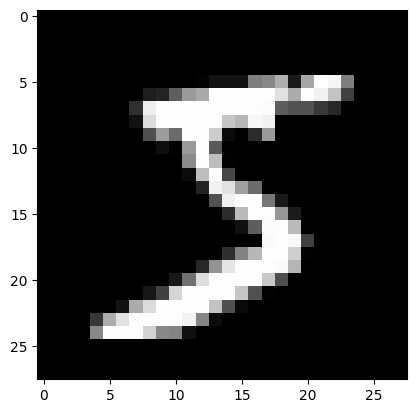

In [ ]:
plot(train.data[0])

MNIST 샘플의 각 픽셀은 0에서부터 255까지의 숫자로 이루어진 grayscale로 구성되어 있습니다.

따라서 255로 각 픽셀 값을 나눠주면 0에서부터 1까지의 값으로 정규화할 수 있습니다.

그리고 현재 신경망은 선형 계층으로만 이루어질 것이기 때문에, 2D 이미지도 1차원 벡터로 평평하게(flatten)해서 나타내야 합니다.

하나의 샘플은 28x28 크기의 픽셀들로 이루어져 있습니다. 따라서 2차원 행렬을 1차원 벡터로 단조롭게 할 경우 784 크기의 벡터가 될 것입니다.

- x.view(x.size(0), -1) : x.size() : 첫 번째 차원의 크기는 x.size(0)으로 유지하고, 나머지 차원의 크기는 -1을 통해 자동으로 계산해서 2차원으로 변경한다.

- x.flatten(1) : 1번 인덱스 차원부터 마지막 차원까지 하나로 합친다.

데이터 전처리
- 0~255 범위의 색상값(픽셀값)을 정규화


In [7]:
X_data=train.data.float()/255.
y_data=train.targets # 전처리 필요없음

X_test=test.data.float()/255.
y_test=test.targets

print(X_data.shape,X_test.shape)
print(y_data.shape,y_test.shape)

torch.Size([60000, 28, 28]) torch.Size([10000, 28, 28])
torch.Size([60000]) torch.Size([10000])


In [8]:
# 정규화 확인
X_data.max()

tensor(1.)

- 2차원 데이터를 선형 신경망에 입력으로 하기 위해서 1차원 데이터로 변환

In [9]:
X_data=X_data.view(X_data.size(0),-1)
X_test=X_test.view(X_test.size(0),-1)

# 크기 확인
print(X_data.shape,X_test.shape)

torch.Size([60000, 784]) torch.Size([10000, 784])


- 신경망 입력과 출력 크기 설정

In [10]:
# 입력 크기 매개변수 정의
input_size=X_data.size(-1)
# 가장 큰 클래스(9)에 +1을 하여 출력의 수를 설정(0부터 시작하므로)
output_size=int(y_data.max())+1

print(f'input_size:{input_size},output_size:{output_size}')

input_size:784,output_size:10


- 훈련데이터와 검증 데이터 분리

In [11]:
from sklearn.model_selection import train_test_split
X_train,X_valid,y_train,y_valid=train_test_split(X_data,y_data,test_size=0.2,random_state=0)
print(f'X_train size:{X_train.size()}')
print(f'X_valid size:{X_valid.size()}')
print(f'y_train size:{y_train.size()}')
print(f'y_valid size:{y_valid.size()}')

X_train size:torch.Size([48000, 784])
X_valid size:torch.Size([12000, 784])
y_train size:torch.Size([48000])
y_valid size:torch.Size([12000])


신경망 설계

In [12]:
from torch.nn.modules.activation import LogSoftmax
model=nn.Sequential(
    nn.Linear(X_train.size(-1),500),
    nn.ReLU(),
    nn.Linear(500,400),
    nn.ReLU(),
    nn.Linear(400,300),
    nn.ReLU(),
    nn.Linear(300,200),
    nn.ReLU(),
    nn.Linear(200,100),
    nn.ReLU(),
    nn.Linear(100,50),
    nn.ReLU(),
    nn.Linear(50,int(y_data.max()+1)),
    # log가 붙어있기 때문에 원핫인코딩하지 않아도 된다
    nn.LogSoftmax()

)

- gpu 설정

In [13]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [15]:
# cpu에서 만든 model을 gpu 장치로 넘김
model=model.to(device)

# 데이터도 gpu 장치로 넘김
X_train=X_train.to(device)
X_valid=X_valid.to(device)
X_test=X_test.to(device)

y_train=y_train.to(device)
y_valid=y_valid.to(device)
y_test=y_test.to(device)

In [16]:
# gpu 연결 확인
# 모델의 파라미터 확인
list(model.parameters())
# next(): 여러 개의 값이 묶여있을 때, 첫 번째 데이터부터 접근해서 상세 속성값을 확인할 수 있도록 연결하는 기능
next(model.parameters()).device

device(type='cuda', index=0)

- 최적화,손실함수

In [17]:
optimizer=optim.Adam(model.parameters())
# NLLLoss()(LogSoftmax 사용했을 때), CrossEntorpy() 중 골라서 사용
loss_func=nn.NLLLoss()
print(optimizer)
print(loss_func)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
NLLLoss()


- 학습 파라미터 설정


In [22]:
n_epochs=10000
batch_size=256
print_interval=10

# 가장 작은 오차
lowest_loss=np.inf
best_mdoel=None
early_stop=50
# 가장 작은 손실값을 가졌을 때의 반복 횟수를 저장
lowest_epoch=np.inf

- 학습구현

In [25]:
train_history,val_history=[],[]

for i in range(n_epochs):
  indices=torch.randperm(X_train.size(0),device=device)

  X_=torch.index_select(X_train,dim=0,index=indices)
  y_=torch.index_select(y_train,dim=0,index=indices)

  X_=X_.split(batch_size,dim=0)
  y_=y_.split(batch_size,dim=0)

  train_loss,val_loss=0,0
  pred_y=[]

  for X_i,y_i in zip(X_,y_):
    pred_y_i=model(X_i)
    loss=loss_func(pred_y_i,y_i)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_loss += float(loss)
  train_loss = train_loss/len(X_)

  # 검증
  with torch.no_grad():
    X_=X_valid.split(batch_size,dim=0)
    y_=y_valid.split(batch_size,dim=0)

    for X_i,y_i in zip(X_,y_):
      pred_y_i=model(X_i)
      loss=loss_func(pred_y_i,y_i)
      val_loss += loss
      pred_y.append(val_loss)
    val_loss=val_loss/len(X_)

    train_history.append(train_loss)
    val_history.append(val_loss)

    if (i+1) % print_interval == 0:
      print(f"Epoch {i+1} : train_loss : {train_loss : 4e}\
      valid_loss:{val_loss:4e}, lowest_loss:{lowest_loss:4e}")

    if val_loss < lowest_loss:
      lowest_loss=val_loss
      lowest_epoch = i
      best_model = deepcopy(model)

    else:
      if i>0 and lowest_epoch + early_stop < i+1:
        print(f"early_stop:{early_stop}")
        break
print(f"{lowest_epoch + 1} epoch에서 가장 낮은 검증 손실값:{lowest_loss:4e}")
# 가장 손실값이 낮을 때의 w,b를 저장해서 model에 초기화
model.load_state_dict(best_model.state_dict())



Epoch 10 : train_loss :  2.184186e-02      valid_loss:1.151503e-01, lowest_loss:9.192832e-02
Epoch 20 : train_loss :  1.026789e-02      valid_loss:1.130444e-01, lowest_loss:9.192832e-02
Epoch 30 : train_loss :  9.214935e-03      valid_loss:1.113559e-01, lowest_loss:9.192832e-02
Epoch 40 : train_loss :  7.380166e-03      valid_loss:1.118604e-01, lowest_loss:9.192832e-02
Epoch 50 : train_loss :  1.139545e-02      valid_loss:1.195951e-01, lowest_loss:9.192832e-02
early_stop:50
5 epoch에서 가장 낮은 검증 손실값:9.192832e-02


<All keys matched successfully>

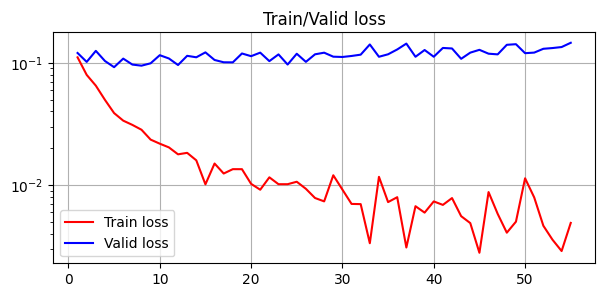

In [27]:
# 손실함수 곡선 확인
# val_history 안에 있는 텐서들이 GPU 위에 있음
# train_loss += float(loss)로 float 형으로 만들었는데 val_loss는 .item()으로 텐서 변환
val_loss_list=[v.cpu().item() for v in val_history]
plt.figure(figsize=(7,3))
plt.grid(True)
plt.title('Train/Valid loss')

plt.plot(range(1,len(train_history)+1),train_history,label='Train loss',color='r')
plt.plot(range(1,len(val_history)+1),val_loss_list,label='Valid loss',color='b')

plt.legend()
plt.yscale('log')
plt.show()

- 테스트 데이터로 모델 평가


In [28]:
test_loss=0
pred_y=[]

model.eval()

with torch.no_grad():
  X_=X_test.split(batch_size,dim=0)
  y_=y_test.split(batch_size,dim=0)

  for X_i,y_i in zip(X_,y_):
    pred_y_i=model(X_i)
    loss=loss_func(pred_y_i,y_i)
    test_loss+=loss
    pred_y.append(pred_y_i)
  test_loss = test_loss/len(X_)

  pred_y = torch.cat(pred_y,dim=0)



/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py:1783: UserWarning: Implicit dimension choice for log_softmax has been deprecated. Change the call to include dim=X as an argument.
  return self._call_impl(*args, **kwargs)


In [29]:
# test_loss 출력
print(f"Test Loss:{test_loss:.4e}")


Test Loss:9.4215e-02


In [30]:
#accuracy 계산
max_class=torch.argmax(pred_y,dim=1)
correct_cnt=(max_class == y_test).sum()
acc=correct_cnt/y_test.size(0)
print(f"Test accuracy:{acc:.4e}")

Test accuracy:9.7280e-01


### 혼동행렬표
- 대각성분의 값들이 맞은 개수
- 대각 성분이 아닌 값은 잘못 예측한 계수


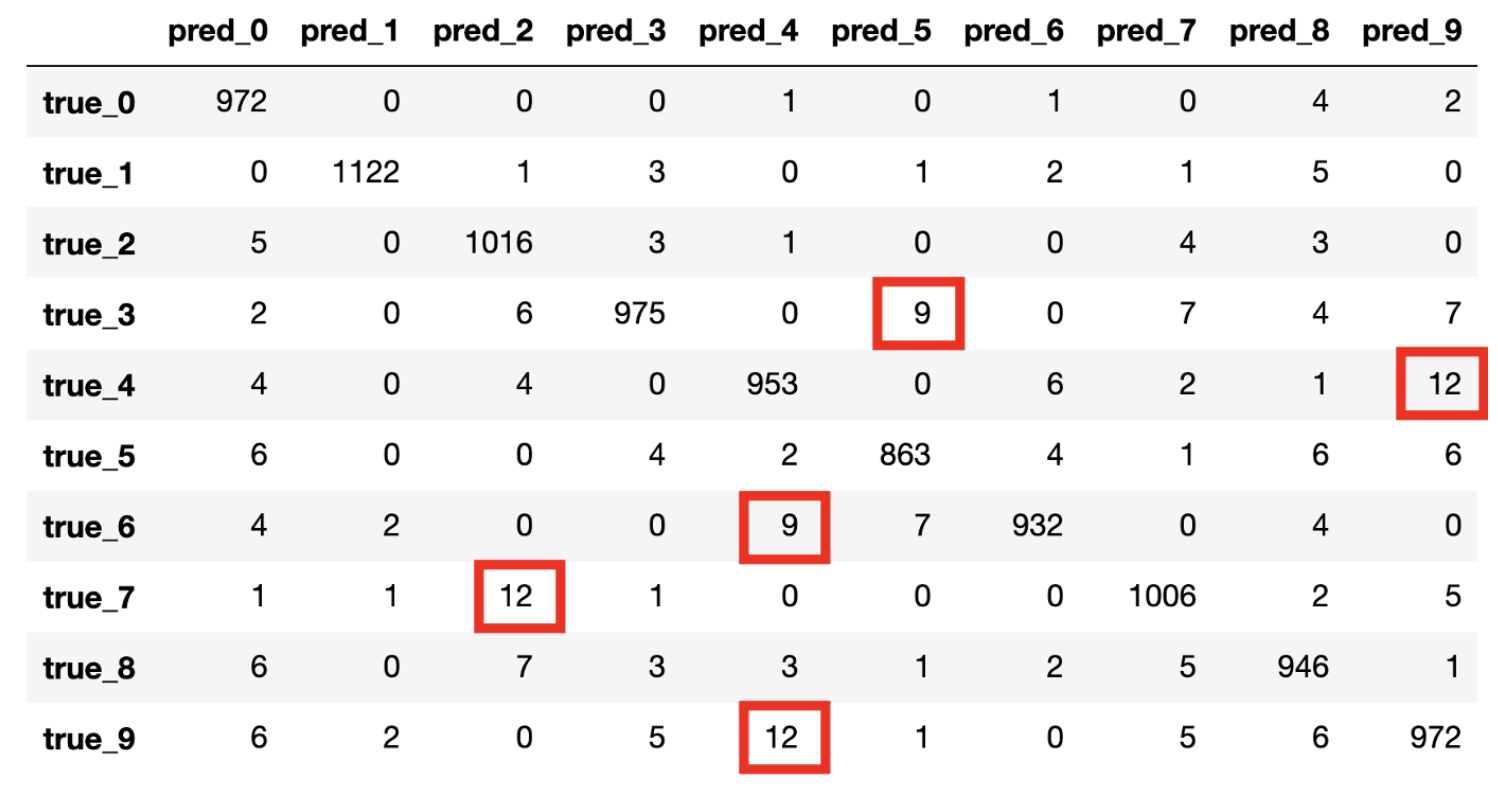

In [32]:
# df으로 각 클래스에 대해서 예측한 결과를 실제 비교해보자
# gpu에 들어 있는 값을 cpu로 옮김
# 인덱스가 실제값
# 컬럼이 예측값
from sklearn.metrics import confusion_matrix

pd.DataFrame(confusion_matrix(y_test.cpu(),torch.argmax(pred_y.cpu(),dim=1)),
             columns = [f'pred_{i}'for i in range(10)],
             index = [f'true_{i}'for i in range(10)]
             )

,pred_0,pred_1,pred_2,pred_3,pred_4,pred_5,pred_6,pred_7,pred_8,pred_9
true_0,969,0,0,0,2,1,1,1,3,3
true_1,0,1123,4,0,0,0,1,0,7,0
true_2,3,1,1018,3,1,0,0,1,5,0
true_3,1,0,9,990,0,3,0,3,3,1
true_4,0,4,4,0,952,0,4,3,0,15
true_5,5,0,0,13,1,857,6,0,8,2
true_6,10,3,1,0,5,11,926,0,2,0
true_7,1,7,20,11,1,0,0,983,0,5
true_8,5,0,7,6,2,4,3,2,938,7
true_9,2,5,0,10,10,0,0,5,5,972
